# 2. Choix et étude de la cible

**Entrée :** `data/batiments_nettoyes.csv` (notebook 1).  
**Sortie :** `data/batiments_cible.csv`, lu par le notebook 3.

### Import des modules

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("data/batiments_nettoyes.csv")
print(df.shape)

(1548, 22)


### Choix de la cible et distribution

count    1.548000e+03
mean     8.860058e+06
std      3.130568e+07
min      5.713320e+04
25%      1.251083e+06
50%      2.732167e+06
75%      7.294487e+06
max      8.739237e+08
Name: SiteEnergyUse(kBtu), dtype: float64


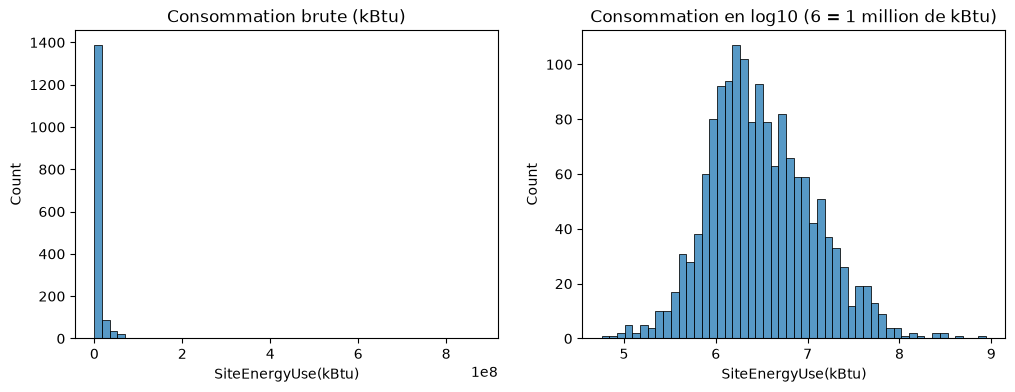

In [3]:
# Cible retenue : la consommation d'énergie totale du bâtiment
cible = "SiteEnergyUse(kBtu)"

# Les émissions de CO2 découlent de la consommation : on les retire (fuite de données)
df = df.drop(columns=["TotalGHGEmissions"])

print(df[cible].describe())

# Distribution brute, puis en log10 (≈ nombre de zéros de la consommation)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df[cible], bins=50, ax=axes[0])
axes[0].set_title("Consommation brute (kBtu)")
sns.histplot(np.log10(df[cible]), bins=50, ax=axes[1])
axes[1].set_title("Consommation en log10 (6 = 1 million de kBtu)")
plt.show()

### Cible et type de bâtiment

A réaliser : boxplots de la cible par `PrimaryPropertyType`, repérer les valeurs aberrantes, retirer les bâtiments incohérents (0 étage, 0 bâtiment).

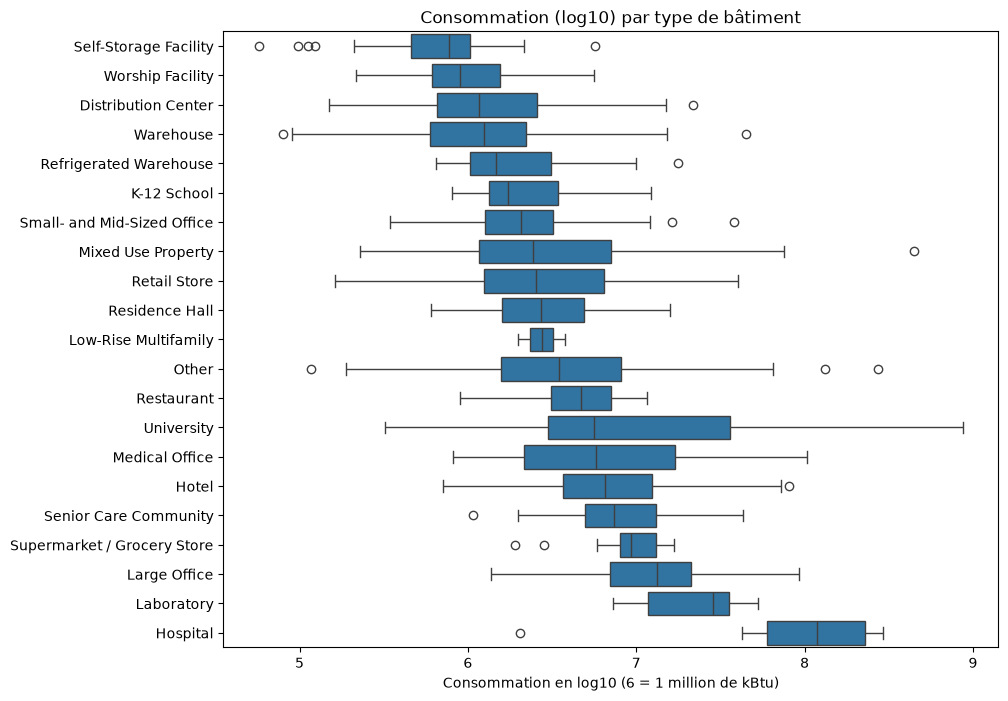

In [4]:
# Boxplots de la conso (en log10) par type de bâtiment
# je classe les types par médiane pour que le graphique soit plus facile à lire
df["log_conso"] = np.log10(df[cible])
ordre = df.groupby("PrimaryPropertyType")["log_conso"].median().sort_values().index

plt.figure(figsize=(10, 8))
sns.boxplot(data=df, x="log_conso", y="PrimaryPropertyType", order=ordre)
plt.title("Consommation (log10) par type de bâtiment")
plt.xlabel("Consommation en log10 (6 = 1 million de kBtu)")
plt.ylabel("")
plt.show()

# colonne juste pour le graphique, je la retire sinon elle part dans le CSV (= la réponse !)
df = df.drop(columns=["log_conso"])

**Ce que je vois :**
- Les **hôpitaux** consomment le plus (médiane ≈ 8,1, environ 120 millions de kBtu) : ouverts 24h/24, avec du matériel médical.
- Les **garde-meubles** consomment le moins (médiane ≈ 5,9, environ 780 000 kBtu) : peu chauffés, presque personne dedans.
- Ça fait environ 2 graduations d'écart, donc un hôpital typique consomme ~150 fois plus qu'un garde-meubles.

➡️ Le type de bâtiment devrait beaucoup aider le modèle, et c'est une info qu'on connaît sans mesurer.

### Bâtiments incohérents

Certaines fiches sont impossibles : 0 bâtiment ou 0 étage alors que le bâtiment a une surface et consomme. On ne connaît pas la vraie valeur, donc je les retire plutôt que d'inventer un chiffre.

In [5]:
# je garde seulement les bâtiments avec au moins 1 bâtiment et au moins 1 étage
n_avant = len(df)
df = df[(df["NumberofBuildings"] > 0) & (df["NumberofFloors"] > 0)]
print(f"{n_avant} -> {len(df)} bâtiments ({n_avant - len(df)} retirés)")

1548 -> 1481 bâtiments (67 retirés)


### Sauvegarde pour le notebook suivant

In [6]:
df.to_csv("data/batiments_cible.csv", index=False)
print(df.shape)

(1481, 21)
